In [10]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data'

### Multiclass Classification
: 결과가 여러개의 클래스로 나오는 경우

## Wine Recognition Dataset
: 와인의 13가지 특징으로 3개의 품종중 어디에 속하는지 다중분류

- 데이터 개수 : 178개
- 입력 특징 : 13개
- 정답 클래스 : 3개(1,2,3 중 하나)

In [11]:

import os
import seaborn as sns
import torch
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import numpy as np
import pandas as pd

torch.manual_seed(42)

In [12]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data'

columns = ['class',
            'Alcohol',
            'Malicacid',
            'Ash',
            'Alcalinity_of_ash',
            'Magnesium',
            'Total_phenols',
            'Flavanoids',
            'Nonflavanoid_phenols',
            'Proanthocyanins',
            'Color_intensity',
            'Hue',
            '0D280_0D315_of_diluted_wines',
            'Proline']

df = pd.read_csv(url, names=columns)
print(df.head())
print('데이터 크기 :', df.shape)
print('클래스별 데이터 개수 :', df["class"].value_counts().sort_index())

# 입력(X) , 출력(y) 분리 및 원본 클래스 1,2,3 -> 0,1,2 변환
x = columns[1:]
X = torch.tensor(df[x].values, dtype=torch.float32)

y = df['class'].values-1
Y = torch.tensor(y, dtype=torch.long)

# train(80%), test(20%)로 분할
train_indices = []
test_indices = []

for class_id in [0, 1, 2]:
    class_indices = np.where(Y == class_id)[0]
    class_indices = class_indices[torch.randperm(len(class_indices)).numpy()]

    split = int(len(class_indices) * 0.8)
    train_indices.extend(class_indices[:split].tolist())
    test_indices.extend(class_indices[split:].tolist())

# 학습/테스트 인덱스 섞기
train_indices = torch.tensor(train_indices, dtype=torch.long)
test_indices = torch.tensor(test_indices, dtype=torch.long)

train_indices = train_indices[torch.randperm(len(train_indices))]
test_indices = test_indices[torch.randperm(len(test_indices))]

# 원본데이터 분리 (train입력, train출력, test 입력, test 출력)
X_train = X[train_indices.numpy()]
X_test = X[test_indices.numpy()]
Y_train = Y[train_indices.numpy()]
Y_test = Y[test_indices.numpy()]

# 표준화
mean = X_train.mean(dim=0)
std = X_train.std(dim=0).clamp(min=1e-5)

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

Y_train = torch.tensor(Y_train, dtype=torch.long)
Y_test = torch.tensor(Y_test, dtype=torch.long)

# 오분류 사례를 원래 단위로 확인하기 위한 테스트 데이터 보관
test_df=df.iloc[test_indices.numpy()].reset_index(drop=True)
print(test_df)

print('X_train :', X_train.shape, X_train.dtype)
print('Y_train :', Y_train.shape, Y_train.dtype)
print('X_test :', X_test.shape, X_test.dtype)
print('Y_test :', Y_test.shape, Y_test.dtype)

print('학습 데이터 클래스 개수 :', torch.bincount(Y_train, minlength=3))
print('테스트 데이터 클래스 개수 :', torch.bincount(Y_test, minlength=3))

   class  Alcohol  Malicacid   Ash  Alcalinity_of_ash  Magnesium  \
0      1    14.23       1.71  2.43               15.6        127   
1      1    13.20       1.78  2.14               11.2        100   
2      1    13.16       2.36  2.67               18.6        101   
3      1    14.37       1.95  2.50               16.8        113   
4      1    13.24       2.59  2.87               21.0        118   

   Total_phenols  Flavanoids  Nonflavanoid_phenols  Proanthocyanins  \
0           2.80        3.06                  0.28             2.29   
1           2.65        2.76                  0.26             1.28   
2           2.80        3.24                  0.30             2.81   
3           3.85        3.49                  0.24             2.18   
4           2.80        2.69                  0.39             1.82   

   Color_intensity   Hue  0D280_0D315_of_diluted_wines  Proline  
0             5.64  1.04                          3.92     1065  
1             4.38  1.05        

C:\Users\mega\AppData\Local\Temp\ipykernel_6472\4256901170.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Y_train = torch.tensor(Y_train, dtype=torch.long)
C:\Users\mega\AppData\Local\Temp\ipykernel_6472\4256901170.py:63: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Y_test = torch.tensor(Y_test, dtype=torch.long)


#### Step 2. DataLoader 생성

In [13]:
BATCH_SIZE=16

train_DS=TensorDataset(X_train, Y_train)
test_DS=TensorDataset(X_test, Y_test)

train_DL=DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL=DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

x_batch, y_batch=next(iter(train_DL))
print('입력 배치 shape', x_batch.shape)
print('정답 배치 shape', y_batch.shape)

입력 배치 shape torch.Size([16, 13])
정답 배치 shape torch.Size([16])


#### Step 3. 학습 모델

In [14]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear=nn.Sequential(nn.Linear(13, 30), nn.ReLU(), nn.Linear(30, 3))

    def forward(self, x):
        return self.linear(x)

model=MLP()

#### Step 4. 모델 학습 시키기

In [15]:
LR = 1e-3
EPOCH = 100

optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

loss_history = []
N = len(train_DL.dataset)

save_path = 'results/MLP_Wine.pt'

# if os.path.exists(save_path):
#     model.load_state_dict(torch.load(save_path))
#     print('기존에 저장된 모델을 불어왔습니다')
# else :
model.train()
for ep in range(EPOCH):
        rloss = 0
        for x_batch, y_batch in train_DL:
            # 예측
            y_hat = model(x_batch)

            # loss
            loss = criterion(y_hat, y_batch)

            # update
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            rloss += loss.item() * x_batch.shape[0]

        epoch_loss = rloss / N
        loss_history.append(epoch_loss)

        if ep % 10 == 0:
            print(f'Epoch : {ep+1}, train loss : {epoch_loss:.4f}')

    # 학습된 모델 저장
os.makedirs('results', exist_ok=True)
torch.save(model.state_dict(), save_path)

Epoch : 1, train loss : 59.3790
Epoch : 11, train loss : 0.7873
Epoch : 21, train loss : 0.5281
Epoch : 31, train loss : 0.4278
Epoch : 41, train loss : 0.3850
Epoch : 51, train loss : 0.3365
Epoch : 61, train loss : 0.3122
Epoch : 71, train loss : 0.2809
Epoch : 81, train loss : 0.2553
Epoch : 91, train loss : 0.2371


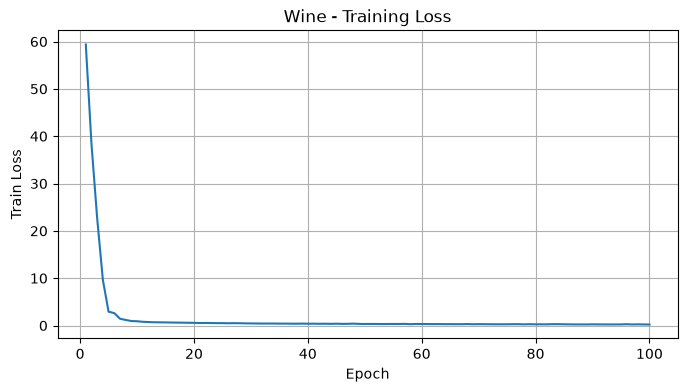

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Train Loss')
plt.title('Wine - Training Loss')
plt.grid(True)

#### Step 5. 모델 테스트 하기

In [17]:
model.eval()

correct = 0
total = 0
# 테스트 데이터 전체의 예측값과 실제 정답을 저장하기 위해 리스트 생성
all_predictions = []
all_targets = []

with torch.no_grad():
    for x_batch, y_batch in test_DL:
        y_hat = model(x_batch)

        pred = y_hat.argmax(dim=1)

        correct += (pred == y_batch).sum().item()
        total += y_batch.size(0)

        all_predictions.append(pred)
        all_targets.append(y_batch)

accuracy = correct / total * 100

y_pred = torch.cat(all_predictions)
y_true = torch.cat(all_targets)
print(y_pred.shape)

print(f'Test accuracy : {correct}/{total} ({accuracy:.1f} %)')

torch.Size([37])
Test accuracy : 36/37 (97.3 %)


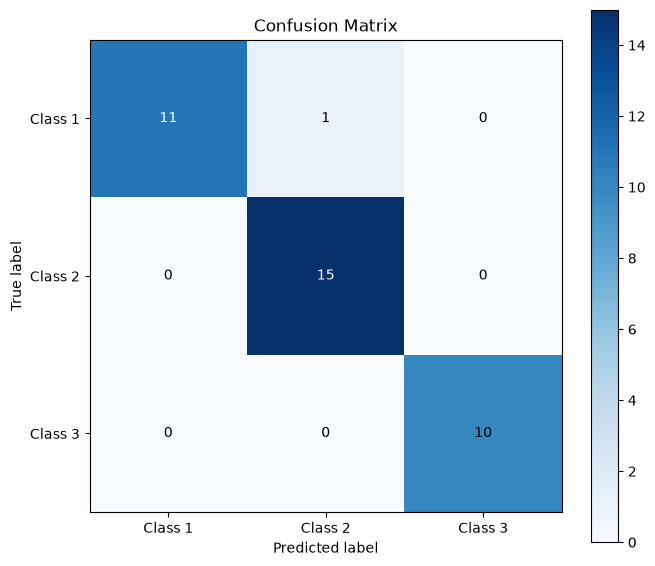

In [19]:
N_CLASS=3

confusion=torch.bincount(N_CLASS *y_true + y_pred, minlength=N_CLASS**2).reshape(N_CLASS, N_CLASS).numpy()

class_name=['Class 1', 'Class 2', 'Class 3']
plt.figure(figsize=(7, 6))
plt.imshow(confusion, cmap='Blues')
plt.title('Confusion Matrix')
plt.colorbar()

for i in range(N_CLASS):
    for j in range(N_CLASS):
        plt.text(j, i, confusion[i, j], ha='center', va='center', color='white' if confusion[i,j] > confusion.max() / 1.5 else 'black')

plt.xticks(range(N_CLASS), class_name)
plt.yticks(range(N_CLASS), class_name)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()

In [20]:
# 클래스별 정답 개수와 오분류 개수
for i, name in enumerate(class_name):
    total_count=int(confusion[i].sum())
    true_count=int(confusion[i, i])
    wrong_count=total_count-true_count
    print(f'{name}: 전체 {total_count}개, 정답 {true_count}, 오분류 {wrong_count}개')

Class 1: 전체 12개, 정답 11, 오분류 1개
Class 2: 전체 15개, 정답 15, 오분류 0개
Class 3: 전체 10개, 정답 10, 오분류 0개
